# LangGraph Multi-Agent Patterns

This notebook contains eight independent multi-agent patterns. Run the setup cells first, then study and test one pattern at a time. Tests are placed directly after their examples.

## Pattern Comparison

| # | Pattern | Main control style | Typical model calls in this test |
|---:|---|---|---:|
| 1 | Router | Select one specialist | 2 |
| 2 | Subagents / Agent-as-Tool | Main agent delegates through tools | Variable |
| 3 | Supervisor | Supervisor repeatedly selects workers | Variable, bounded |
| 4 | Handoff | Triage transfers control to one specialist | 2 |
| 5 | Swarm | Agents hand control to one another | Variable |
| 6 | Hierarchical Supervisor | Top supervisor selects a team subgraph | 3 |
| 7 | Parallel Collaboration with `Send` | Dynamic fan-out and aggregation | `N + 2` |
| 8 | Coordinator-Guided Peer Network | Coordinator repeatedly selects a peer | Variable, bounded |

> The examples are independent. Running every test will make many API calls, so run one pattern at a time while teaching.

In [1]:
from typing import (
    TypedDict,
    Literal,
    Annotated,
)

import operator

from dotenv import load_dotenv
from pydantic import BaseModel

from langchain_openai import ChatOpenAI
from langchain_core.messages import (
    HumanMessage,
    AIMessage,
)
from langchain_core.tools import tool
from langchain.agents import create_agent

from langgraph.graph import (
    StateGraph,
    START,
    END,
    MessagesState,
)
from langgraph.types import (
    Command,
    Send,
)
from langgraph.checkpoint.memory import InMemorySaver

In [2]:
load_dotenv()


True

In [3]:
model = ChatOpenAI(
    model="gpt-4.1-mini",
    temperature=0,
)

In [4]:
def print_title(title: str):
    print("\n")
    print("=" * 80)
    print(title)
    print("=" * 80)

In [5]:
def show_graph(compiled_graph):
    """Print the generated graph as Mermaid text."""
    print(compiled_graph.get_graph().draw_mermaid())

## 1. Router Multi-Agent

**How it works:** A router reads the request and selects exactly one specialist. Only that specialist answers.

**Real-world example:** A customer-support desk sends a duplicate payment issue to billing, a login issue to technical support, and a general question to general support.

```text
User → Router → One Specialist → Response
```


In [6]:
class RouterDecision(BaseModel):
    route: Literal[
        "technical",
        "billing",
        "general",
    ]

In [7]:
router_model = model.with_structured_output(RouterDecision)

In [8]:
router_model.invoke("can you resolve the bug in my system?")

RouterDecision(route='technical')

In [9]:
class RouterState(TypedDict):
    query: str
    route: str
    response: str

### Router and specialist nodes

In [10]:
def router_node(state: RouterState,):

    decision = router_model.invoke(
        f"""
Route the following user query to exactly one specialist.

Available specialists:
- technical
- billing
- general

User query:
{state["query"]}
"""
    )

    return {
        "route": decision.route
    }

In [11]:
def technical_agent(state: RouterState):
    response = model.invoke(
        f"""
You are a technical support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [12]:
def billing_agent(state: RouterState,):

    response = model.invoke(
        f"""
You are a billing support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [13]:
def general_agent(state: RouterState,):

    response = model.invoke(
        f"""
You are a general support specialist.

Answer this query:
{state["query"]}
"""
    )

    return {
        "response": response.content
    }

In [14]:
def route_to_specialist(state: RouterState,):
    return state["route"]

In [15]:
def build_router_multi_agent():
    builder = StateGraph(RouterState)
    
    builder.add_node(
        "router",
        router_node,
    )

    builder.add_node(
        "technical",
        technical_agent,
    )

    builder.add_node(
        "billing",
        billing_agent,
    )

    builder.add_node(
        "general",
        general_agent,
    )

    builder.add_edge(
        START,
        "router",
    )

    builder.add_conditional_edges(
        "router",
        route_to_specialist,
        {
            "technical": "technical",
            "billing": "billing",
            "general": "general",
        },
    )

    builder.add_edge(
        "technical",
        END,
    )

    builder.add_edge(
        "billing",
        END,
    )

    builder.add_edge(
        "general",
        END,
    )

    return builder.compile()


### Generated graph structure

This cell builds the graph and prints its Mermaid definition without invoking the model.

In [16]:
router_graph = build_router_multi_agent()

In [17]:
show_graph(router_graph)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	router(router)
	technical(technical)
	billing(billing)
	general(general)
	__end__([<p>__end__</p>]):::last
	__start__ --> router;
	router -.-> billing;
	router -.-> general;
	router -.-> technical;
	billing --> __end__;
	general --> __end__;
	technical --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



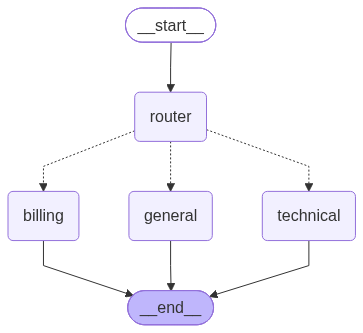

In [18]:
router_graph

better terminology:
“This is a router-based LLM workflow with specialized LLM nodes.”

Not a full multi-agent system in the strict sense.

If technical_agent does something like this:
Technical Agent
   ↓
Decides:
Do I need documentation search?
   ↓
Calls search tool
   ↓
Checks result
   ↓
Maybe calls another tool
   ↓
Decides when to stop

then calling it a proper agent is more justified.

Simple distinction:

Your current code:

LLM Router
   ↓
Fixed specialist node
   ↓
LLM response

= Routing Workflow

Proper agent version:
LLM Router
   ↓
Technical Agent
   ↓
LLM decides action
   ├── Search tool
   ├── API tool
   ├── Database tool
   └── Final answer
        ↺

In class, you can say:
“Although we may name these nodes technical agent or billing agent, in this implementation they are specialized LLM nodes rather than fully autonomous agents. The overall architecture is primarily a routing workflow.”

And remember this line:
Role ≠ Agent. Autonomy and action-selection make it agentic.

##### This is a router-based LLM workflow with specialized LLM nodes.

### Test

**Expected behavior:** The duplicate-charge query is routed to `billing`, and the billing specialist produces the response.

**Model calls:** 2.

In [19]:
def run_router_multi_agent():

    print_title(
        "1. ROUTER MULTI-AGENT"
    )

    graph = (build_router_multi_agent())

    result = graph.invoke(
        {
            "query":"My subscription payment was charged twice.",
            "route": "",
            "response": "",
        }
    )

    print(
        "Selected Agent:",
        result["route"],
    )

    print(
        "\nResponse:\n",
        result["response"],
    )

    return result


In [20]:
router_result = run_router_multi_agent()



1. ROUTER MULTI-AGENT
Selected Agent: billing

Response:
 I'm sorry to hear that your subscription payment was charged twice. To help resolve this issue, could you please provide the following details?

1. Your account email or username  
2. The date of the duplicate charges  
3. Any transaction IDs or payment confirmation numbers you have  

Once I have this information, I can investigate the charges and assist you with a refund if applicable.


## 2. Subagents / Agent-as-Tool ( re-Act  & action)

**How it works:** A main coordinator remains in control and `calls specialist agents as tools`. Each specialist has a focused role.

**Real-world example:** A consultant asks a researcher for facts, a math expert for a calculation, and a writer to present the combined answer clearly.

```text
User → Main Agent → Specialist Tools → Main Agent → Final Answer
```

### Create the specialist subagents

In [8]:
from langchain.agents import create_agent

In [9]:
research_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a research specialist. "
        "Provide concise factual research."
    ),
    name="research_subagent",
)

In [10]:
math_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a math specialist. "
        "Solve calculations accurately."
    ),
    name="math_subagent",
)

In [11]:
writing_subagent = create_agent(
    model=model,
    tools=[],
    system_prompt=(
        "You are a professional writing specialist. "
        "Rewrite information clearly and concisely."
    ),
    name="writing_subagent",
)

### Wrap subagents as tools and create the coordinator


In [12]:
def get_last_message_content(result,):

    return (
        result["messages"][-1].content
    )

In [13]:
@tool
def ask_research_agent(task: str,) -> str:
    """
    Delegate a research task to the research specialist.
    """

    result = research_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [14]:
@tool
def ask_math_agent(
    task: str,
) -> str:
    """
    Delegate a mathematical task to the math specialist.
    """

    result = math_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [15]:
@tool
def ask_writing_agent(
    task: str,
) -> str:
    """
    Delegate a writing task to the writing specialist.
    """

    result = writing_subagent.invoke(
        {
            "messages": [
                {
                    "role": "user",
                    "content": task,
                }
            ]
        }
    )

    return get_last_message_content(
        result
    )

In [16]:
main_delegation_agent = create_agent(
    model=model,
    tools=[
        ask_research_agent,
        ask_math_agent,
        ask_writing_agent,
    ],
    system_prompt="""
You are the main coordinator.

You have three specialist subagents:
1. Research specialist
2. Math specialist
3. Writing specialist

Delegate work to the appropriate specialist tools.
You may call multiple specialists when necessary.
Finally provide one clear answer to the user.
""",
    name="main_coordinator",
)


### Generated graph structure

This cell builds the graph and prints its Mermaid definition without invoking the model.

In [17]:
show_graph(main_delegation_agent)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools -.-> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



                    Main Coordinator Agent
                            |
               LLM decides which tool to call
                            |
          ┌─────────────────┼─────────────────┐
          ↓                           ↓                 ↓
 ask_research_agent   ask_math_agent   ask_writing_agent
          ↓                 ↓       ↓
 Research Subagent     Math Subagent     Writing Subagent

“This is a subagent-as-tool multi-agent architecture where a coordinator agent dynamically delegates tasks to specialized subagents.”

Aur exact distinction:
Main Coordinator
= Proper agent
  because it dynamically selects tools/subagents.

Research / Math / Writing subagents
= Specialized agent/worker objects,
  but currently they have no tools,
  so their behavior is essentially specialized LLM generation.

Previous router example:
Router
  ↓
technical node
  ↓
END

= Routing workflow

Current example:
Coordinator Agent
   ↓
decides which subagent tool to call
   ↓
Subagent
   ↓
result comes back
   ↓
Coordinator can call another subagent
   ↓
Final answer

= Multi-agent / subagent delegation pattern

“In this architecture, the coordinator is clearly agentic because it dynamically decides which subagent to invoke. The specialist subagents are created as agents, but since they currently have no tools, they behave mainly as specialized LLM workers.”

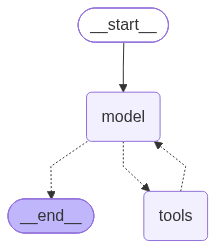

In [21]:
main_delegation_agent

### Test

**Expected behavior:** The coordinator may delegate research, multiplication, and writing before returning one answer.

**Model calls:** Variable because the main agent decides which tools to call.

In [22]:
def run_subagents():

    print_title(
        "2. SUBAGENTS / AGENT-AS-TOOL"
    )

    result = (
        main_delegation_agent.invoke(
            {
                "messages": [
                    {
                        "role": "user",
                        "content": (
                            "Explain RAG briefly, calculate "
                            "25 * 16, and present the answer "
                            "in a clean professional format."
                        ),
                    }
                ]
            }
        )
    )

    print(
        result["messages"][-1].content
    )

    return result


In [23]:
subagents_result = run_subagents()



2. SUBAGENTS / AGENT-AS-TOOL
**Retrieval-Augmented Generation (RAG)**

Retrieval-Augmented Generation (RAG) is an advanced natural language processing technique that combines retrieval-based methods with generative models. It enhances the generation of accurate and contextually relevant responses by first retrieving pertinent information from a large external knowledge base and then using this information to guide the generation process. This approach improves the quality and factual correctness of the output, making it particularly useful in applications such as question answering and knowledge-intensive tasks.

---

**Calculation: 25 × 16**

To calculate 25 multiplied by 16:

\[
25 \times 16 = 25 \times (10 + 6) = (25 \times 10) + (25 \times 6) = 250 + 150 = 400
\]

**Result:** 400


In [26]:
subagents_result

{'messages': [HumanMessage(content='Explain RAG briefly, calculate 25 * 16, and present the answer in a clean professional format.', additional_kwargs={}, response_metadata={}, id='16732155-3b10-4217-8fc9-bf0916002736'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 173, 'total_tokens': 238, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_bff0d0112a', 'id': 'chatcmpl-EWB33Ej1zh2xmN737YEPmwiNLS3Pi', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, name='main_coordinator', id='lc_run--01a1140b-b0ff-7350-972d-8f9e78206e7d-0', tool_c

In [29]:
subagents_result["messages"][-1].content

'**Retrieval-Augmented Generation (RAG)**\n\nRetrieval-Augmented Generation (RAG) is an advanced natural language processing technique that combines retrieval-based methods with generative models. It enhances the generation of accurate and contextually relevant responses by first retrieving pertinent information from a large external knowledge base and then using this information to guide the generation process. This approach improves the quality and factual correctness of the output, making it particularly useful in applications such as question answering and knowledge-intensive tasks.\n\n---\n\n**Calculation: 25 × 16**\n\nTo calculate 25 multiplied by 16:\n\n\\[\n25 \\times 16 = 25 \\times (10 + 6) = (25 \\times 10) + (25 \\times 6) = 250 + 150 = 400\n\\]\n\n**Result:** 400'

'**Retrieval-Augmented Generation (RAG)**\n\nRetrieval-Augmented Generation (RAG) is an advanced natural language processing technique that combines retrieval-based methods with generative models. It enhances the generation of accurate and contextually relevant responses by first retrieving pertinent information from a large external knowledge base and then using this information to guide the generation process. This approach improves the quality and factual correctness of the output, making it particularly useful in applications such as question answering and knowledge-intensive tasks.\n\n---\n\n**Calculation: 25 × 16**\n\nTo calculate 25 multiplied by 16:\n\n\\[\n25 \\times 16 = 25 \\times (10 + 6) = (25 \\times 10) + (25 \\times 6) = 250 + 150 = 400\n\\]\n\n**Result:** 400'

## 3. Supervisor Multi-Agent


**How it works:** A central supervisor repeatedly selects the next worker, reviews accumulated work, and finishes when enough work is available. A six-turn limit prevents an endless loop.


**Real-world example:** A project manager assigns research, calculation, and writing tasks one at a time, then creates the final training note.

```text
Supervisor → Worker → Supervisor → Another Worker → Finish
```



### State and supervisor decision schema

In [30]:
class SupervisorDecision(BaseModel):

    next_agent: Literal[
        "research_agent",
        "math_agent",
        "writer_agent",
        "FINISH",
    ]

    instruction: str

In [31]:
class SupervisorState(TypedDict):
    task: str
    next_agent: str
    instruction: str
    worker_outputs: Annotated[
        list[str],
        operator.add,
    ]
    final_answer: str
    supervisor_turns: int

In [33]:
supervisor_router = ( model.with_structured_output(SupervisorDecision))

In [35]:
supervisor_router.invoke("can you research about the RAG?")

SupervisorDecision(next_agent='research_agent', instruction='Please research about RAG (Retrieval-Augmented Generation), including its definition, applications, and significance in AI.')

### Supervisor and worker nodes


In [36]:
def supervisor(
    state: SupervisorState,
):

    supervisor_turns = state.get(
        "supervisor_turns",
        0,
    ) + 1

    completed_work = "\n\n".join(
        state.get(
            "worker_outputs",
            [],
        )
    )

    if supervisor_turns >= 6 and completed_work:
        return {
            "next_agent": "FINISH",
            "instruction": (
                "Maximum supervisor turns reached. "
                "Create the final answer."
            ),
            "supervisor_turns": supervisor_turns,
        }

    decision = supervisor_router.invoke(
        f"""
You are a supervisor managing three workers:

- research_agent
- math_agent
- writer_agent

Original task:
{state["task"]}

Work completed so far:
{completed_work or "No worker has completed any work yet."}

Choose the next worker.

Rules:
- Use research_agent for research/explanation.
- Use math_agent for calculations.
- Use writer_agent when a polished final presentation is useful.
- If enough work is complete, choose FINISH.
- Do not repeatedly call the same worker unless required.

Return:
- next_agent
- instruction for that worker
"""
    )

    return {
        "next_agent":
        decision.next_agent,

        "instruction":
        decision.instruction,

        "supervisor_turns":
        supervisor_turns,
    }


In [37]:
def supervisor_research_worker(
    state: SupervisorState,
):

    response = model.invoke(
        f"""
You are the research worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Perform only the research/explanation part.
"""
    )

    return {
        "worker_outputs": [
            "RESEARCH WORKER:\n"
            + response.content
        ]
    }

In [38]:
def supervisor_math_worker(
    state: SupervisorState,
):

    response = model.invoke(
        f"""
You are the math worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Perform only the calculation/reasoning part.
"""
    )

    return {
        "worker_outputs": [
            "MATH WORKER:\n"
            + response.content
        ]
    }



In [39]:
def supervisor_writer_worker(
    state: SupervisorState,
):

    previous_work = "\n\n".join(
        state.get(
            "worker_outputs",
            [],
        )
    )

    response = model.invoke(
        f"""
You are the writing worker.

Original task:
{state["task"]}

Supervisor instruction:
{state["instruction"]}

Available previous work:
{previous_work}

Create a polished response or writing contribution.
"""
    )

    return {
        "worker_outputs": [
            "WRITER WORKER:\n"
            + response.content
        ]
    }

In [40]:
def supervisor_finish(
    state: SupervisorState,
):

    completed_work = "\n\n".join(
        state["worker_outputs"]
    )

    response = model.invoke(
        f"""
You are the supervisor.

Create the final answer for the user.

Original task:
{state["task"]}

Worker outputs:
{completed_work}
"""
    )

    return {
        "final_answer":
        response.content
    }

In [41]:
def supervisor_route(
    state: SupervisorState,
):

    return state["next_agent"]

### Build the graph

In [42]:
def build_supervisor_graph():

    builder = StateGraph(
        SupervisorState
    )

    builder.add_node(
        "supervisor",
        supervisor,
    )

    builder.add_node(
        "research_agent",
        supervisor_research_worker,
    )

    builder.add_node(
        "math_agent",
        supervisor_math_worker,
    )

    builder.add_node(
        "writer_agent",
        supervisor_writer_worker,
    )

    builder.add_node(
        "finish",
        supervisor_finish,
    )

    builder.add_edge(
        START,
        "supervisor",
    )

    builder.add_conditional_edges(
        "supervisor",
        supervisor_route,
        {
            "research_agent":
            "research_agent",

            "math_agent":
            "math_agent",

            "writer_agent":
            "writer_agent",

            "FINISH":
            "finish",
        },
    )

    builder.add_edge(
        "research_agent",
        "supervisor",
    )

    builder.add_edge(
        "math_agent",
        "supervisor",
    )

    builder.add_edge(
        "writer_agent",
        "supervisor",
    )

    builder.add_edge(
        "finish",
        END,
    )

    return builder.compile()


### Generated graph structure

This cell builds the graph and prints its Mermaid definition without invoking the model.

In [43]:
supervisor_graph = build_supervisor_graph()
show_graph(supervisor_graph)


---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	research_agent(research_agent)
	math_agent(math_agent)
	writer_agent(writer_agent)
	finish(finish)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	math_agent --> supervisor;
	research_agent --> supervisor;
	supervisor -. &nbsp;FINISH&nbsp; .-> finish;
	supervisor -.-> math_agent;
	supervisor -.-> research_agent;
	supervisor -.-> writer_agent;
	writer_agent --> supervisor;
	finish --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



“This is a supervisor-based agentic workflow where the supervisor dynamically delegates tasks to specialized LLM workers.”
The supervisor is clearly agentic because:
LLM
↓
observes state
↓
decides the next action
↓
routes dynamically
↓
checks new results
↓
decides again

The workers are not fully autonomous agents yet.
If the workers also have tools:
Research Agent
   ↓
Search Web?
Search DB?
Call API?
   ↓
Observe
   ↓
Maybe call another tool
   ↓
Return result

then it becomes a much stronger multi-agent system.



`Current flow`

START
  ↓
Supervisor
  ↓
Choose worker
  ↓
Worker
  ↓
Supervisor
  ↓
Choose another worker
  ↓
Worker
  ↓
Supervisor
  ↓
FINISH
  ↓
Final Answer
  ↓
END

And this:
if supervisor_turns >= 6:


is just a safety guard.
If the supervisor keeps looping even after 6 turns, we force it to FINISH.

Best class line:
“In the supervisor pattern, a central LLM supervisor dynamically decides which specialized worker should execute next based on the task and the work completed so far. The workers return their outputs to the supervisor, and this loop continues until the supervisor decides to finish.”

For your current code:
Supervisor = agentic controller
Research / Math / Writer = specialized LLM workers

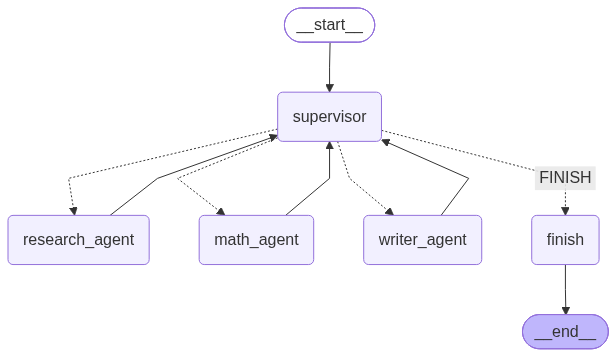

In [44]:
supervisor_graph

### Test

**Expected behavior:** The supervisor chooses useful workers and eventually returns a final training note. `supervisor_turns` cannot exceed the safety limit.

**Model calls:** Variable and bounded by the supervisor-turn limit.

In [45]:
def run_supervisor():

    print_title(
        "3. SUPERVISOR MULTI-AGENT"
    )

    graph = build_supervisor_graph()

    result = graph.invoke(
        {
            "task": (
                "Explain Retrieval-Augmented Generation, "
                "calculate 48 * 25, and present everything "
                "as a short training note."
            ),

            "next_agent": "",
            "instruction": "",
            "worker_outputs": [],
            "final_answer": "",
            "supervisor_turns": 0,
        },

        config={
            "recursion_limit": 20
        },
    )

    print(
        result["final_answer"]
    )

    return result


In [46]:
supervisor_result = run_supervisor()




3. SUPERVISOR MULTI-AGENT
**Training Note: Retrieval-Augmented Generation (RAG) and Practical Calculation Example**

Retrieval-Augmented Generation (RAG) is a technique in natural language processing that enhances generative models by incorporating relevant external information. Instead of relying solely on a model’s internal knowledge, RAG first retrieves pertinent documents or data from an external knowledge base based on the input query. This retrieved information is then used as additional context to guide the generative model in producing more accurate, informed, and contextually relevant responses. By combining retrieval and generation, RAG overcomes the limitations of fixed knowledge within models and improves performance on tasks requiring up-to-date or specialized information.

**Example Calculation:**

Calculate 48 × 25:

48 × 25 = 48 × (20 + 5)  
= (48 × 20) + (48 × 5)  
= 960 + 240  
= 1200

This stepwise breakdown illustrates how complex problems can be simplified by div

## 4. Handoff Multi-Agent

**How it works:** The triage agent selects a specialist and uses `Command(goto=...)` to transfer graph control. The selected specialist completes the request.

**Real-world example:** A reception desk transfers a 401 API error to technical support rather than trying to solve it itself.

```text
User → Triage ─┬→ Billing → END
               └→ Technical → END
```

In [9]:
### State and handoff decision schema

In [10]:
class HandoffDecision(BaseModel):
    target: Literal[
        "billing_agent",
        "technical_agent",
    ]
    reason: str

In [11]:
handoff_router_model = (model.with_structured_output(HandoffDecision))

In [12]:
handoff_router_model.invoke("I am facing issue in my internet while connecting to the teams")

HandoffDecision(target='technical_agent', reason='The user is experiencing internet connectivity issues affecting Microsoft Teams, which requires technical support to diagnose and resolve network problems.')

### Triage and specialist nodes

In [13]:
class HandoffState(MessagesState):
    active_agent: str

In [15]:
def triage_handoff_agent(state: HandoffState,) -> Command[Literal["billing_agent","technical_agent",]]:

    latest_user_message = (
        state["messages"][-1].content
    )

    decision = (
        handoff_router_model.invoke(
            f"""
You are a triage agent.

Choose which specialist should handle this user request.

billing_agent:
Payments, invoices, refunds, subscriptions.

technical_agent:
Software errors, login problems, API issues, technical troubleshooting.

User request:
{latest_user_message}
"""
        )
    )

    return Command(
        goto=decision.target,

        update={
            "active_agent":decision.target,
            "messages": [
                AIMessage(
                    content=(
                        "Handoff reason: "
                        + decision.reason
                    )
                )
            ],
        },
    )

In [16]:
def handoff_billing_agent(
    state: HandoffState,
):

    response = model.invoke(
        [
            {
                "role": "system",
                "content":
                "You are a billing support specialist.",
            },

            *state["messages"],
        ]
    )

    return {
        "messages": [
            response
        ],

        "active_agent":
        "billing_agent",
    }


In [19]:
def handoff_technical_agent(
    state: HandoffState,
):

    response = model.invoke(
        [
            {
                "role": "system",
                "content":
                "You are a technical support specialist.",
            },

            *state["messages"],
        ]
    )

    return {
        "messages": [
            response
        ],

        "active_agent":
        "technical_agent",
    }

In [21]:
def build_handoff_graph():

    builder = StateGraph(
        HandoffState
    )

    builder.add_node(
        "triage",
        triage_handoff_agent,
    )

    builder.add_node(
        "billing_agent",
        handoff_billing_agent,
    )

    builder.add_node(
        "technical_agent",
        handoff_technical_agent,
    )

    builder.add_edge(
        START,
        "triage",
    )

    builder.add_edge(
        "billing_agent",
        END,
    )

    builder.add_edge(
        "technical_agent",
        END,
    )

    return builder.compile()


In [22]:
handoff_graph = build_handoff_graph()
show_graph(handoff_graph)

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	triage(triage)
	billing_agent(billing_agent)
	technical_agent(technical_agent)
	__end__([<p>__end__</p>]):::last
	__start__ --> triage;
	triage -.-> billing_agent;
	triage -.-> technical_agent;
	billing_agent --> __end__;
	technical_agent --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



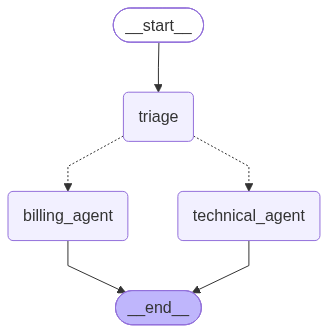

In [23]:
handoff_graph

### Test

**Expected behavior:** The 401 authentication problem is handed to `technical_agent`, which writes the final response.

**Model calls:** 2.


In [27]:
def run_handoffs():

    print_title(
        "4. HANDOFF MULTI-AGENT"
    )

    graph = build_handoff_graph()

    result = graph.invoke(
        {
            "messages": [
                HumanMessage(
                    content=(
                        "My API keeps returning a 401 authentication error."
                    )
                )
            ],

            "active_agent":
            "triage",
        }
    )

    print(
        "Active Agent:",
        result["active_agent"],
    )

    print(
        "\nFinal Response:\n",
        result["messages"][-1].content,
    )

    return result


In [28]:
handoff_result = run_handoffs()



4. HANDOFF MULTI-AGENT
Active Agent: technical_agent

Final Response:
 A 401 authentication error means your API request is not properly authenticated. Here are some common causes and steps to troubleshoot:

1. **Check your API key or token:**  
   - Ensure you are including the correct API key or token in the request headers or parameters as required by the API.  
   - Verify the key/token has not expired or been revoked.

2. **Verify the authentication method:**  
   - Confirm you are using the correct authentication scheme (e.g., Bearer token, Basic Auth).  
   - Make sure the Authorization header is formatted correctly, for example:  
     `Authorization: Bearer YOUR_ACCESS_TOKEN`

3. **Check the request URL and endpoint:**  
   - Some APIs require authentication only on certain endpoints.  
   - Ensure you are calling the correct endpoint that requires authentication.

4. **Review API documentation:**  
   - Double-check the authentication requirements and examples in the API do